# 実験結果の解析

In [12]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# プロジェクトルートディレクトリの検出
project_dir = Path.cwd().resolve()
if not (project_dir / "configs").is_dir():
    project_dir = project_dir.parent

# 実験結果ディレクトリの指定 (exp_v4 用に変更)
experiment_name = "exp_v4_grid_search"
experiment_dir = project_dir / "data" / experiment_name

# 必須ファイルのチェック (V4で生成されるファイル群)
required_files = [
    "config_used.json",
    "raw_data.csv",
    "summary_data.csv",
    "time_series_data.csv",
    "genotype_time_series_data.csv",
]

if any(not (experiment_dir / name).is_file() for name in required_files):
    raise FileNotFoundError(f"実験結果ファイルが不足しています。先に実験を実行してください: {experiment_dir}")

# 使用した設定ファイルの読み込み
with (experiment_dir / "config_used.json").open(encoding="utf-8") as file:
    config = json.load(file)

# CSV データの読み込み
raw_df = pd.read_csv(experiment_dir / "raw_data.csv")
summary_df = pd.read_csv(experiment_dir / "summary_data.csv")
time_series_df = pd.read_csv(experiment_dir / "time_series_data.csv")
genotype_df = pd.read_csv(experiment_dir / "genotype_time_series_data.csv")

# 設定内容の表示（Jupyter Notebook等でそのまま確認可能）
config


{'experiment_name': 'exp_v4_grid_search',
 'agent_class': 'AgentV4',
 'field_class': 'FieldV4',
 'simulation': {'total_steps': 10000,
  'eval_start_step': 5001,
  'num_runs': 1,
  'base_seed': 42,
  'workers': 5},
 'grid_parameters': {'initial_food_prob': [0.1],
  'step_food_prob': [0.01],
  'food_lifetime_steps': [2],
  'death_threshold': [-100, -80, -60, -40, -20, -5],
  'transfer_amount': [3]},
 'fixed_field_parameters': {'field_size': 10,
  'initial_agents': 20,
  'mutation_rate': 0.05,
  'energy_loss_per_step': 0.1,
  'reward_food': 1.0,
  'clone_threshold': 100.0}}

In [13]:
# 時系列データおよび遺伝子型データの表示・確認ブロック

time_series_path = experiment_dir / "time_series_data.csv"
genotype_path = experiment_dir / "genotype_time_series_data.csv"

time_series_df = None
genotype_df = None

# 1. 時系列データの確認と読み込み
if time_series_path.is_file():
    time_series_df = pd.read_csv(time_series_path)
    if time_series_df.empty:
        print("時系列データは空です。1000step以上の実験を実行してください。")
    else:
        print("--- 時系列データ (time_series_df) ---")
        display(time_series_df.head())
else:
    print("時系列データがありません。実験を再実行して time_series_data.csv を作成してください。")

# 2. 遺伝子型時系列データの確認と読み込み
if genotype_path.is_file():
    genotype_df = pd.read_csv(genotype_path)
    if genotype_df.empty:
        print("遺伝子型時系列データは空です。1000step以上の実験を実行してください。")
    else:
        print("\n--- 遺伝子型時系列データ (genotype_df) ---")
        display(genotype_df.head())
else:
    print("遺伝子型時系列データがありません。実験を再実行して genotype_time_series_data.csv を作成してください。")

--- 時系列データ (time_series_df) ---


,initial_food_prob,step_food_prob,food_lifetime_steps,death_threshold,transfer_amount,run_id,seed,step,population,altruism_count,altruism_rate
0,0.1,0.01,2,-20,3,0,42,1,20,6,0.300000
1,0.1,0.01,2,-20,3,0,42,1000,5,194,0.023567
2,0.1,0.01,2,-20,3,0,42,2000,7,0,0.000000
3,0.1,0.01,2,-20,3,0,42,3000,6,0,0.000000
4,0.1,0.01,2,-20,3,0,42,4000,6,0,0.000000



--- 遺伝子型時系列データ (genotype_df) ---


,initial_food_prob,step_food_prob,food_lifetime_steps,death_threshold,transfer_amount,run_id,seed,step,genotype,population
0,0.1,0.01,2,-20,3,0,42,1,1011,1
1,0.1,0.01,2,-20,3,0,42,1,10101,1
2,0.1,0.01,2,-20,3,0,42,1,111110,1
3,0.1,0.01,2,-20,3,0,42,1,1000010,1
4,0.1,0.01,2,-20,3,0,42,1,1000100,1


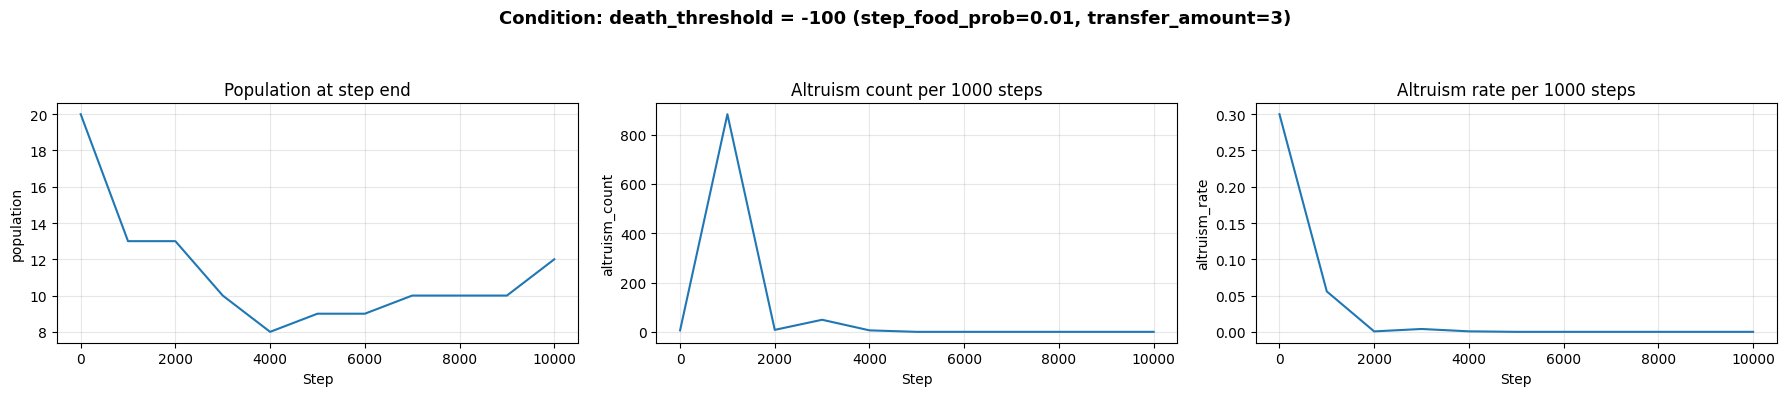

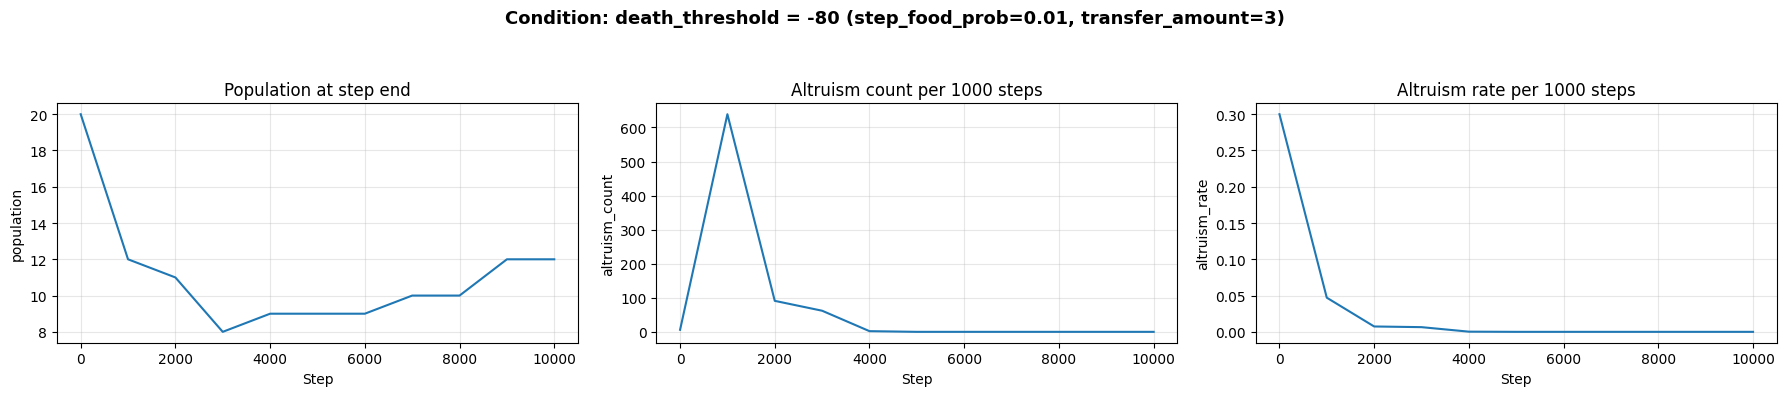

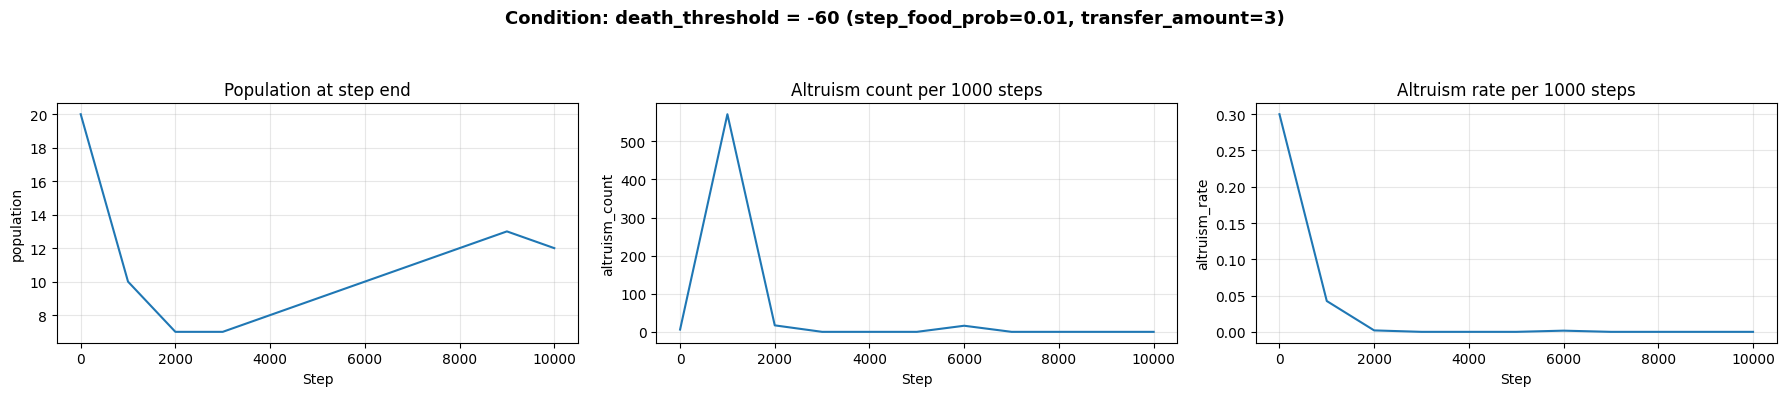

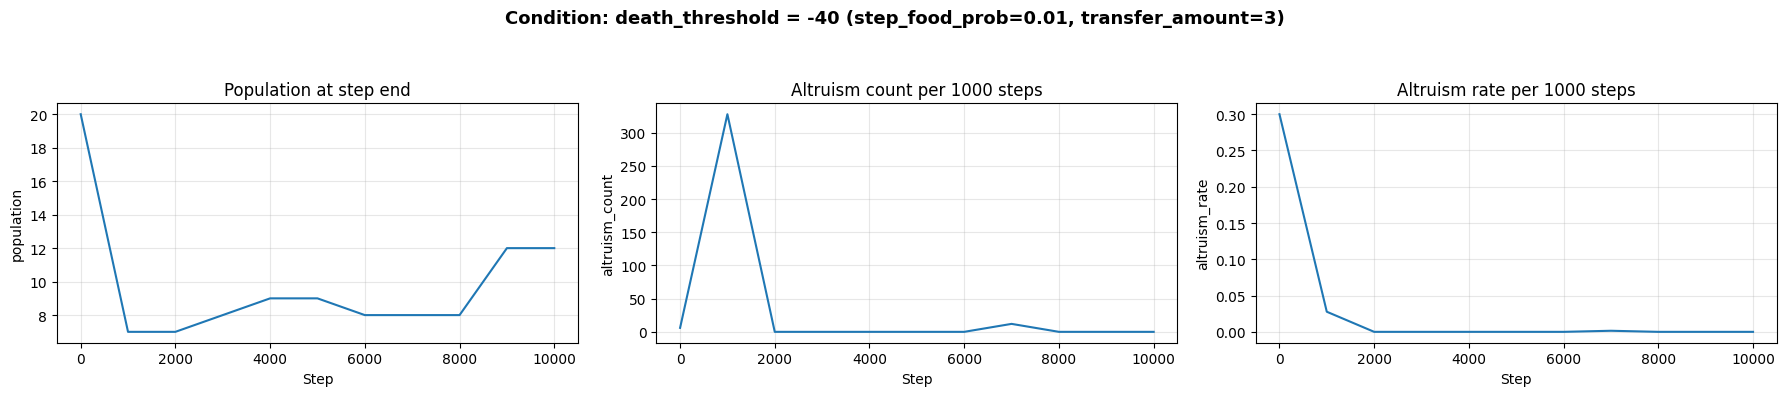

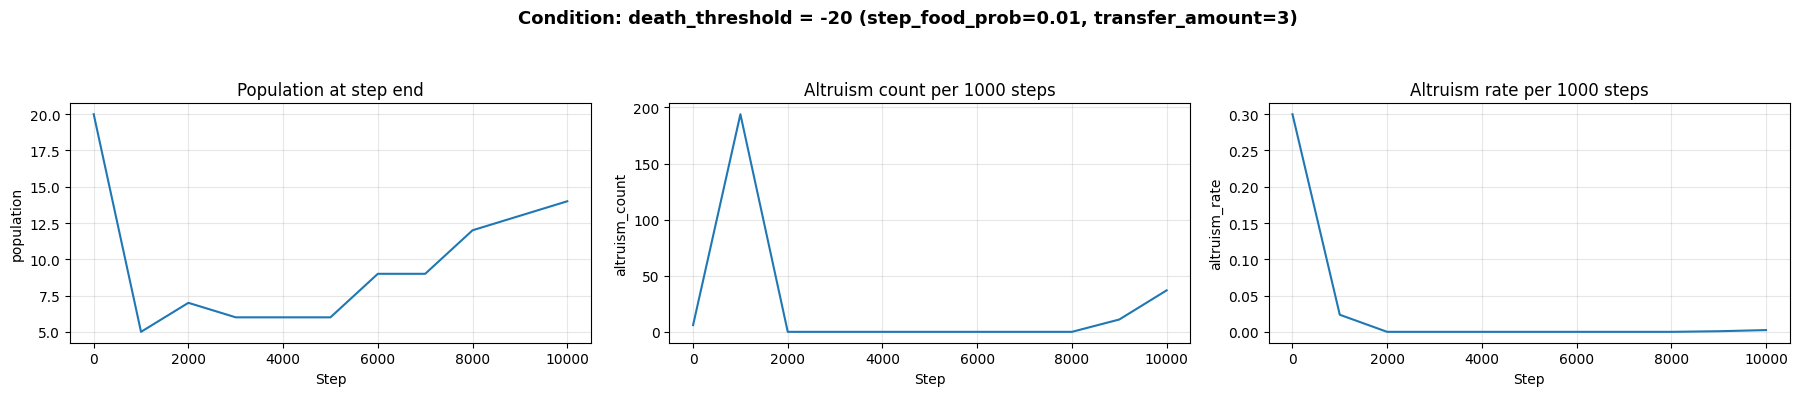

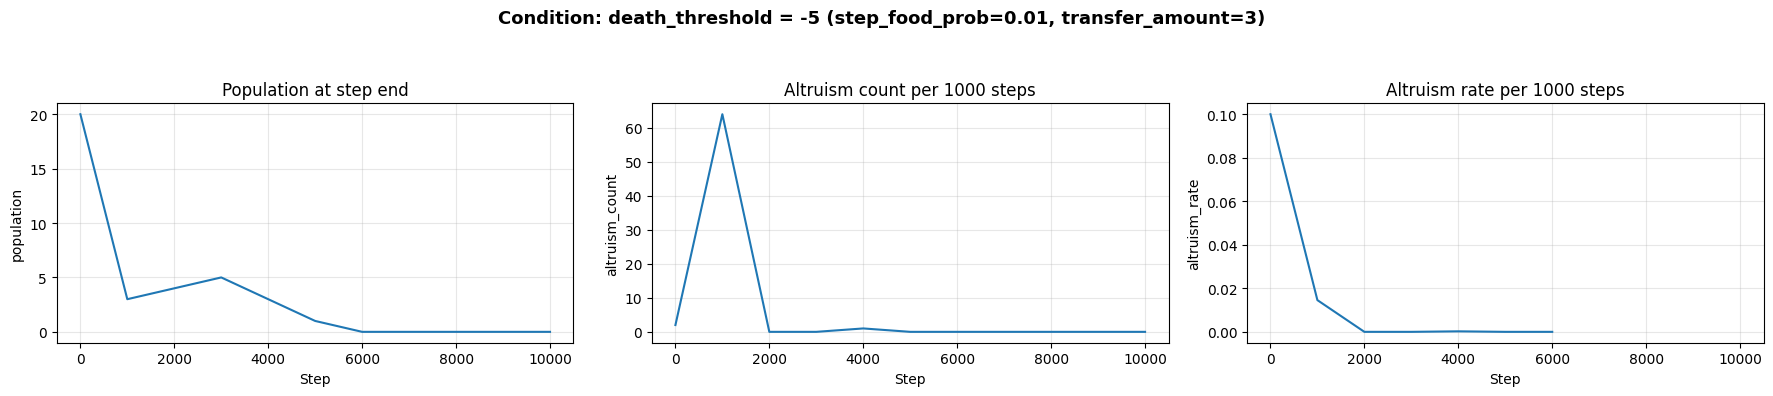

In [14]:
if time_series_df is not None and not time_series_df.empty:
    # 描画対象の列とタイトルの定義
    metrics = ["population", "altruism_count", "altruism_rate"]
    titles = [
        "Population at step end",
        "Altruism count per 1000 steps",
        "Altruism rate per 1000 steps",
    ]

    # death_threshold (グリッドパラメータ) の条件ごとにループ処理して描画
    for death_threshold, group_df in time_series_df.groupby(
        "death_threshold", sort=True
    ):
        group_df = group_df.sort_values("step")

        # 1行3列のグラフを作成
        fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharex=True)

        for metric, axis, title in zip(metrics, axes, titles):
            axis.plot(
                group_df["step"],
                group_df[metric],
                color="tab:blue",
                linewidth=1.5,
            )
            axis.set_title(title)
            axis.set_xlabel("Step")
            axis.set_ylabel(metric)
            axis.grid(True, alpha=0.3)

        # その条件のパラメータ情報を表示
        step_food_prob = group_df["step_food_prob"].iloc[0]
        transfer_amount = group_df["transfer_amount"].iloc[0]

        fig.suptitle(
            f"Condition: death_threshold = {death_threshold:g} "
            f"(step_food_prob={step_food_prob:g}, transfer_amount={transfer_amount:g})",
            fontsize=13,
            fontweight="bold",
        )
        fig.tight_layout(rect=(0, 0, 1, 0.92))
        plt.show()
